# Klasifikasi Gangguan Listrik Tiga Fase — Scikit-Learn
**Reno Prasetyo Rochmat dan tim | S1 Teknik Elektro, Telkom University**

Notebook ini menjalankan pengumpulan/pemeriksaan data, feature engineering, training,
validasi, evaluasi, dan ekspor model untuk deployment. Targetnya mengenali **kondisi saat ini**,
bukan meramalkan kapan gangguan akan terjadi.

**Sumber:** [Electrical Fault Detection and Classification](https://www.kaggle.com/datasets/esathyaprakash/electrical-fault-detection-and-classification).
Gunakan `classData.csv` untuk klasifikasi enam kelas. `detect_dataset.csv` adalah dataset deteksi
biner yang berbeda dan **tidak digabungkan** karena tidak ada kunci pasangan sampel yang terverifikasi.
Data benchmark berasal dari simulasi; hasilnya belum membuktikan kemampuan pada sistem listrik nyata.

**Tujuan pembelajaran:** memahami seluruh kode, menjelaskan pemisahan X/y, mencegah kebocoran data,
membandingkan model, membaca confusion matrix, dan memuat model tanpa training ulang.


## Cara menjalankan di Google Colab
1. Buka https://colab.research.google.com/ dan pilih **File > Upload notebook**.
2. Unggah `TugasColab_Klasifikasi_Gangguan_Listrik.ipynb` ini.
3. Simpan salinan ke Google Drive melalui **File > Save a copy in Drive**.
4. Gunakan runtime Python dengan **Hardware accelerator: None / CPU**.
5. Pilih **Runtime > Run all**. Saat tombol unggah muncul, pilih **archive.zip** yang sudah
   diunduh dari Kaggle. ZIP tidak perlu diekstrak. `classData.csv` langsung juga didukung.
6. Tunggu semua sel selesai. Sel terakhir mengunduh **paket_deployment.zip**.
7. Jika unduhan belum muncul, jalankan kembali sel terakhir atau unduh melalui panel Files.

Ada dua berkas yang berbeda: `.ipynb` adalah notebook kode; `archive.zip` adalah data input.
Tidak perlu API token Kaggle, memasang Google Drive, atau menyalin kode sel satu per satu.
Jika data sudah ada dalam sesi yang sama, sel unggah akan memakainya kembali.
Data dan hasil di `/content` hanya berada dalam runtime; simpan notebook ke Drive dan unduh
paket hasil setelah eksekusi. Notebook tidak mengunggah hasil atau video ke layanan lain.

Training dilakukan di Colab. kemudian menguji paket model di Jetson; membuat
web/API yang memanggil pipeline. Notebook ini belum membuat web atau menguji perangkat Jetson.


In [1]:
from pathlib import Path
import sys, io, json, zipfile, hashlib, platform, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                            recall_score, f1_score, classification_report,
                            ConfusionMatrixDisplay)

SEED = 42
N_JOBS = 2
DATA_PATH = None  # Opsional: isi jalur ZIP atau classData.csv yang sudah ada di runtime.
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
CONTENT_ROOT = Path('/content') if IN_COLAB else Path.cwd()
INPUT_DIR = CONTENT_ROOT / 'upload_gangguan_listrik'
INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT = (CONTENT_ROOT if IN_COLAB else CONTENT_ROOT / 'output') / 'hasil_gangguan_listrik'
OUT.mkdir(parents=True, exist_ok=True)
FEATURES = ['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']
LABEL_COLS = ['G', 'C', 'B', 'A']  # Urutan kode HARUS GCBA
CLASS_NAMES = {
    '0000': 'Normal',
    '1001': 'A-G: fase A ke tanah',
    '1011': 'AB-G: fase A dan B ke tanah',
    '0110': 'BC: antar fase B dan C',
    '0111': 'ABC: tiga fase',
    '1111': 'ABC-G: tiga fase ke tanah',
}
CLASSES = sorted(CLASS_NAMES)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
print('Python:', platform.python_version(), '| Scikit-Learn:', sklearn.__version__)
print('Output:', OUT)


Python: 3.13.18 | Scikit-Learn: 1.6.1
Output: /content/hasil_gangguan_listrik


## 1. Mengunggah dataset dan mengaudit sumber data
Jalankan sel unggah berikut, lalu pilih **archive.zip** dari laptop. ZIP dibaca langsung tanpa
mengekstrak seluruh arsip. Dari dua CSV di dalamnya, hanya `classData.csv` yang dipakai untuk
klasifikasi enam kelas. Hash SHA-256 dicatat untuk reproduksibilitas.


In [2]:
if DATA_PATH is not None:
    DATA_PATH = Path(DATA_PATH)
    if not DATA_PATH.is_file():
        raise FileNotFoundError(f'File belum ditemukan: {DATA_PATH}')
else:
    cached = [p for p in [INPUT_DIR / 'dataset.zip', INPUT_DIR / 'classData.csv'] if p.is_file()]
    if len(cached) > 1:
        raise ValueError('Ada dua sumber tersimpan. Isi DATA_PATH dengan satu sumber yang benar.')
    if cached:
        DATA_PATH = cached[0]
        print('Memakai dataset yang sudah diunggah dalam sesi ini.')
    elif IN_COLAB:
        print('Pilih archive.zip (dataset), bukan file notebook .ipynb.')
        uploaded = colab_files.upload()
        if len(uploaded) != 1:
            raise ValueError('Unggah tepat satu ZIP dataset atau classData.csv.')
        uploaded_name, uploaded_bytes = next(iter(uploaded.items()))
        suffix = Path(uploaded_name).suffix.lower()
        if suffix not in {'.zip', '.csv'}:
            raise ValueError('Format harus .zip atau .csv, bukan .ipynb.')
        DATA_PATH = INPUT_DIR / ('dataset.zip' if suffix == '.zip' else 'classData.csv')
        DATA_PATH.write_bytes(uploaded_bytes)
        del uploaded, uploaded_bytes
    else:
        raise RuntimeError('Buka notebook di Google Colab atau isi DATA_PATH untuk uji lokal.')
print('Dataset siap:', DATA_PATH)


Pilih archive.zip (dataset), bukan file notebook .ipynb.


Saving archive.zip to archive.zip
Dataset siap: /content/upload_gangguan_listrik/dataset.zip


In [3]:
def load_classification_file():
    if DATA_PATH is not None:
        candidates = [Path(DATA_PATH)]
    else:
        roots = [INPUT_DIR, Path.cwd() / 'upload', Path.cwd() / 'data']
        candidates = sorted({p for root in roots if root.exists() for p in root.rglob('classData.csv')})
        if not candidates:
            candidates = []
            for root in roots:
                if not root.exists():
                    continue
                for path in sorted(root.rglob('*.zip')):
                    with zipfile.ZipFile(path) as z:
                        if any(Path(n).name == 'classData.csv' for n in z.namelist()):
                            candidates.append(path)
    if len(candidates) != 1:
        raise ValueError('Diperlukan tepat satu sumber classData.csv. Jalankan sel unggah ZIP '
                         'atau isi DATA_PATH. Kandidat: ' + str(candidates))
    path = candidates[0]
    if path.suffix.lower() == '.zip':
        with zipfile.ZipFile(path) as z:
            members = [n for n in z.namelist() if Path(n).name == 'classData.csv']
            if len(members) != 1:
                raise ValueError('ZIP harus berisi tepat satu classData.csv.')
            raw = z.read(members[0])
        source = path.name + '::' + members[0]
    else:
        raw = path.read_bytes()
        source = path.name
    return pd.read_csv(io.BytesIO(raw)), source, hashlib.sha256(raw).hexdigest()

raw_df, source_name, source_sha256 = load_classification_file()
print('Sumber:', source_name)
print('SHA-256:', source_sha256)
print('Ukuran:', raw_df.shape)
print(raw_df.head().to_string(index=False))
missing_columns = set(FEATURES + LABEL_COLS) - set(raw_df.columns)
if missing_columns:
    raise ValueError('Kolom wajib hilang: ' + str(missing_columns))
print('Nilai kosong per kolom:\n', raw_df.isna().sum().to_string())
print('Duplikat baris:', int(raw_df.duplicated(subset=FEATURES + LABEL_COLS).sum()))


Sumber: dataset.zip::classData.csv
SHA-256: c8e7d1f2a6d4aefd74b5ed48d9ca4afdfdf2a5b676a5ed0935625e48972a36b2
Ukuran: (7861, 10)
 G  C  B  A          Ia          Ib          Ic       Va        Vb        Vc
 1  0  0  1 -151.291812   -9.677452   85.800162 0.400750 -0.132935 -0.267815
 1  0  0  1 -336.186183  -76.283262   18.328897 0.312732 -0.123633 -0.189099
 1  0  0  1 -502.891583 -174.648023  -80.924663 0.265728 -0.114301 -0.151428
 1  0  0  1 -593.941905 -217.703359 -124.891924 0.235511 -0.104940 -0.130570
 1  0  0  1 -643.663617 -224.159427 -132.282815 0.209537 -0.095554 -0.113983
Nilai kosong per kolom:
 G     0
C     0
B     0
A     0
Ia    0
Ib    0
Ic    0
Va    0
Vb    0
Vc    0
Duplikat baris: 0


### Pembersihan dan definisi target
Label harus berisi 0 atau 1. Baris fitur nonnumerik/tidak hingga ditandai sebagai missing value,
lalu imputasinya dipelajari **hanya dari data training** dalam pipeline. Duplikat persis dibuang
sebelum split agar salinan baris yang sama tidak tersebar ke train dan test.

`GCBA` merupakan **target**, bukan input. Untuk tugas ini, empat indikator digabung menjadi
satu target kategorikal, misalnya `1001` berarti fase A terhubung ke tanah.


In [4]:
df = raw_df.loc[:, LABEL_COLS + FEATURES].copy()
for col in LABEL_COLS:
    df[col] = pd.to_numeric(df[col], errors='raise')
    if not df[col].isin([0, 1]).all():
        raise ValueError(f'Label {col} harus bernilai 0 atau 1 tanpa missing value.')
df[LABEL_COLS] = df[LABEL_COLS].astype(int)
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df[FEATURES] = df[FEATURES].replace([np.inf, -np.inf], np.nan)
before = len(df)
df = df.drop_duplicates(subset=LABEL_COLS + FEATURES).reset_index(drop=True)
df['fault_code'] = df[LABEL_COLS].astype(str).agg(''.join, axis=1)
unknown = set(df['fault_code']) - set(CLASSES)
if unknown:
    raise ValueError('Kombinasi label belum didokumentasikan: ' + str(unknown))
if set(df['fault_code']) != set(CLASSES):
    raise ValueError('Notebook ini mengharapkan keenam kelas benchmark.')
print('Baris duplikat dibuang:', before - len(df))
print('Missing fitur setelah konversi:', int(df[FEATURES].isna().sum().sum()))
class_counts = df['fault_code'].value_counts().reindex(CLASSES)
summary = pd.DataFrame({'kode': CLASSES, 'nama': [CLASS_NAMES[c] for c in CLASSES],
                        'jumlah': class_counts.values})
summary['persen'] = (summary['jumlah'] / len(df) * 100).round(2)
print(summary.to_string(index=False))
summary.to_csv(OUT / 'distribusi_kelas.csv', index=False)


Baris duplikat dibuang: 0
Missing fitur setelah konversi: 0
kode                        nama  jumlah  persen
0000                      Normal    2365   30.09
0110      BC: antar fase B dan C    1004   12.77
0111              ABC: tiga fase    1096   13.94
1001        A-G: fase A ke tanah    1129   14.36
1011 AB-G: fase A dan B ke tanah    1134   14.43
1111   ABC-G: tiga fase ke tanah    1133   14.41


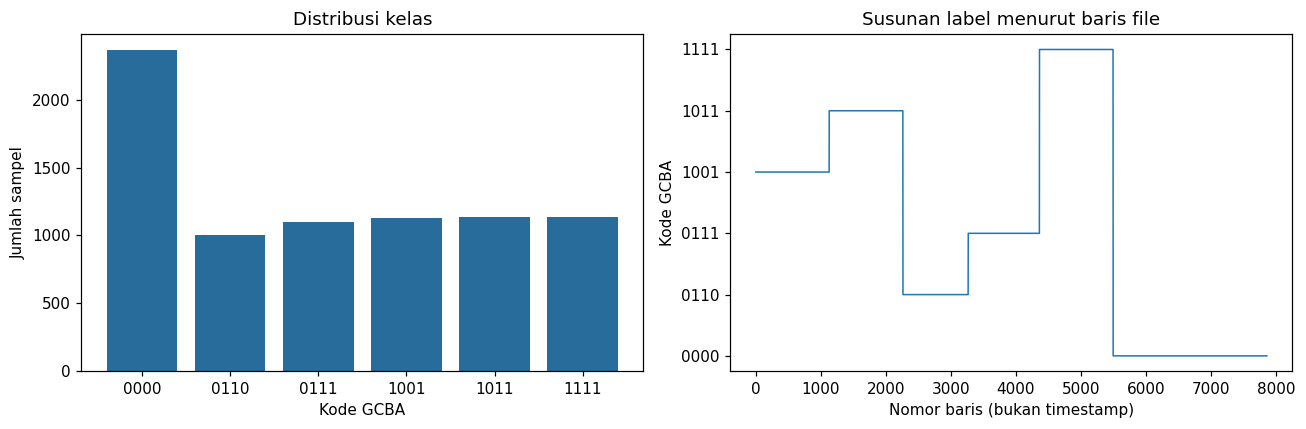

Jumlah blok label berurutan: 6


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(CLASSES, class_counts.values, color='#276c9b')
axes[0].set(title='Distribusi kelas', xlabel='Kode GCBA', ylabel='Jumlah sampel')
axes[1].plot(np.arange(len(df)), pd.Categorical(df['fault_code'], categories=CLASSES).codes, lw=1)
axes[1].set_yticks(range(len(CLASSES)), CLASSES)
axes[1].set(title='Susunan label menurut baris file', xlabel='Nomor baris (bukan timestamp)', ylabel='Kode GCBA')
fig.tight_layout()
fig.savefig(OUT / 'distribusi_dan_urutan.png', bbox_inches='tight')
plt.show()
print('Jumlah blok label berurutan:', int(df['fault_code'].ne(df['fault_code'].shift()).sum()))


## 2. Feature engineering dan pemisahan data
Enam fitur asli dipertahankan sebagai baseline yang mudah direproduksi di web dan Jetson.
Scaling dipelajari dalam pipeline; ini penting untuk KNN. Tidak ada indikator label atau nomor
baris yang masuk ke X. Satuan fisik dan skala sensor perlu dikonfirmasi dari dokumentasi sumber;
nilai Va/Vb/Vc tidak otomatis diperlakukan sebagai pembacaan volt jaringan nyata.

**Dua holdout yang tidak digunakan untuk training/tuning:**
- Sisihkan 20% baris terakhir **di setiap kelas** sebagai uji blok urutan.
- Sisihkan 5% tepat sebelum bagian tersebut sebagai jarak/purge; baris ini tidak dipakai.
- Dari 75% sisanya, ambil 80% untuk train dan 20% untuk uji acak berstrata.

Proporsi total menjadi sekitar **60% train, 15% uji acak, 20% uji blok, 5% purge**.
Ini sengaja lebih ketat daripada hanya split acak karena file tersusun dalam blok kelas.
Uji blok tetap bukan pengujian pada kejadian gangguan baru: file tidak menyediakan ID kejadian
atau timestamp yang dapat diverifikasi. Nomor baris hanya dipakai untuk merancang split.


In [6]:
pool_idx, block_idx, purge_idx = [], [], []
for fault_code in CLASSES:
    idx = df.index[df['fault_code'].eq(fault_code)].to_numpy()
    boundary_train = int(np.floor(0.75 * len(idx)))
    boundary_test = int(np.floor(0.80 * len(idx)))
    pool_idx.extend(idx[:boundary_train])
    purge_idx.extend(idx[boundary_train:boundary_test])
    block_idx.extend(idx[boundary_test:])
train_idx, test_idx = train_test_split(
    np.array(pool_idx), test_size=0.20, stratify=df.loc[pool_idx, 'fault_code'], random_state=SEED)
block_idx, purge_idx = np.array(block_idx), np.array(purge_idx)
partitions = [set(train_idx), set(test_idx), set(block_idx), set(purge_idx)]
assert sum(map(len, partitions)) == len(df)
assert len(set.union(*partitions)) == len(df)
assert all(partitions[i].isdisjoint(partitions[j]) for i in range(4) for j in range(i))
X_train, y_train = df.loc[train_idx, FEATURES], df.loc[train_idx, 'fault_code']
X_test, y_test = df.loc[test_idx, FEATURES], df.loc[test_idx, 'fault_code']
X_block, y_block = df.loc[block_idx, FEATURES], df.loc[block_idx, 'fault_code']
if X_train.isna().all().any():
    raise ValueError('Ada fitur yang seluruh data latihnya kosong; periksa dataset.')
split_manifest = pd.DataFrame({'row_id': df.index, 'split': 'purge'})
for ids, label in [(train_idx, 'train'), (test_idx, 'test_random'), (block_idx, 'test_block')]:
    split_manifest.loc[ids, 'split'] = label
split_manifest['fault_code'] = df['fault_code']
split_manifest.to_csv(OUT / 'split_manifest.csv', index=False)
print(pd.crosstab(split_manifest['fault_code'], split_manifest['split']).to_string())
print('X_train:', X_train.shape, '| X_test:', X_test.shape, '| X_block:', X_block.shape)


split       purge  test_block  test_random  train
fault_code                                       
0000          119         473          355   1418
0110           50         201          151    602
0111           54         220          164    658
1001           57         226          169    677
1011           57         227          170    680
1111           57         227          170    679
X_train: (4714, 6) | X_test: (1179, 6) | X_block: (1574, 6)


### Eksplorasi fitur dan outlier menggunakan data latih
Nilai ekstrem dapat merupakan ciri gangguan yang ingin dikenali. Karena itu, aturan IQR hanya
digunakan untuk audit; **tidak otomatis menghapus outlier** atau mengubah distribusi kelas.
Korelasi dihitung pada data latih, bukan digunakan untuk mengintip label holdout.


              Ia         Ib         Ic         Va         Vb         Vc
count  4714.0000  4714.0000  4714.0000  4714.0000  4714.0000  4714.0000
mean    -18.1514     5.3231     4.4594     0.0041     0.0107    -0.0148
std     466.4116   451.7455   384.3713     0.2842     0.2980     0.3020
min    -883.5423  -900.5270  -883.3578    -0.6207    -0.6059    -0.6127
25%    -247.6289  -137.3543   -73.7301    -0.0890    -0.0919    -0.2333
50%     -10.0801    13.9709    -8.2495     0.0037     0.0026    -0.0081
75%     107.3636   130.4086    48.6082     0.1208     0.1458     0.1757
max     885.7161   889.8689   901.1012     0.5953     0.6279     0.5997
Jumlah penanda IQR (dipertahankan):
 Ia     933
Ib    1459
Ic    1568
Va     913
Vb     837
Vc       0


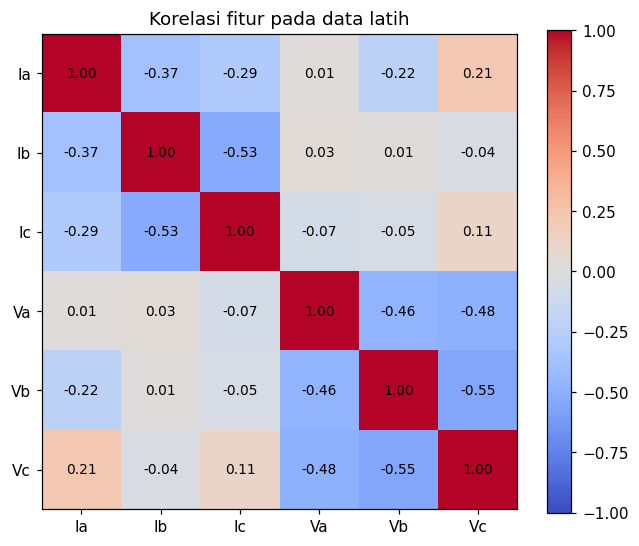

In [7]:
print(X_train.describe().round(4).to_string())
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
outlier_count = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum()
print('Jumlah penanda IQR (dipertahankan):\n', outlier_count.to_string())
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(FEATURES)), FEATURES)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('Korelasi fitur pada data latih')
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT / 'korelasi_train.png', bbox_inches='tight')
plt.show()


## 3. Pelatihan dan perbandingan model
`DummyClassifier` adalah pembanding sederhana yang selalu memilih kelas terbanyak.
Decision Tree, Random Forest, dan KNN dibandingkan dengan **5-fold Stratified Cross-Validation**
pada train saja. Setiap fold mempelajari imputasi dan scaling dari bagian training-nya sendiri.

Pemilihan model menggunakan rata-rata **macro F1**, yang memberi bobot sama untuk setiap kelas.
Skor training dan validasi serta selisihnya membantu membahas overfitting; tidak ada ambang
selisih universal. CV acak tetap dapat optimistis untuk data yang berkorelasi menurut urutan.


In [8]:
def make_pipeline(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', estimator),
    ])

models = {
    'Dummy': make_pipeline(DummyClassifier(strategy='most_frequent')),
    'DecisionTree': make_pipeline(DecisionTreeClassifier(random_state=SEED, class_weight='balanced')),
    'RandomForest': make_pipeline(RandomForestClassifier(n_estimators=120, random_state=SEED,
                                                         class_weight='balanced', n_jobs=1)),
    'KNN': make_pipeline(KNeighborsClassifier(n_neighbors=7)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, pipeline in models.items():
    result = cross_validate(pipeline, X_train, y_train, cv=cv,
                            scoring={'f1_macro': 'f1_macro', 'accuracy': 'accuracy'},
                            return_train_score=True, n_jobs=N_JOBS, error_score='raise')
    rows.append({'model': name,
                 'train_f1_macro': result['train_f1_macro'].mean(),
                 'cv_f1_macro': result['test_f1_macro'].mean(),
                 'cv_f1_std': result['test_f1_macro'].std(),
                 'cv_accuracy': result['test_accuracy'].mean(),
                 'mean_fit_seconds': result['fit_time'].mean()})
comparison = pd.DataFrame(rows).sort_values('cv_f1_macro', ascending=False).reset_index(drop=True)
comparison['train_cv_gap'] = comparison['train_f1_macro'] - comparison['cv_f1_macro']
comparison.to_csv(OUT / 'perbandingan_cv.csv', index=False)
print(comparison.round(5).to_string(index=False))


       model  train_f1_macro  cv_f1_macro  cv_f1_std  cv_accuracy  mean_fit_seconds  train_cv_gap
         KNN         0.87509      0.79678    0.00366      0.82690           0.02528       0.07831
DecisionTree         1.00000      0.78841    0.00338      0.82032           0.21396       0.21159
RandomForest         1.00000      0.78439    0.00723      0.81672           2.80891       0.21561
       Dummy         0.07708      0.07708    0.00009      0.30081           0.02896       0.00000


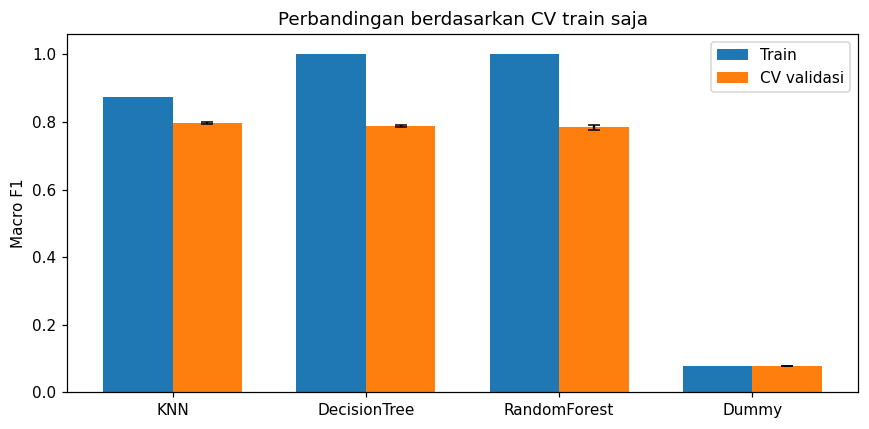

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(comparison))
ax.bar(positions - 0.18, comparison['train_f1_macro'], width=0.36, label='Train')
ax.bar(positions + 0.18, comparison['cv_f1_macro'], width=0.36,
       yerr=comparison['cv_f1_std'], capsize=4, label='CV validasi')
ax.set_xticks(positions, comparison['model'])
ax.set(ylim=(0, 1.06), ylabel='Macro F1', title='Perbandingan berdasarkan CV train saja')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'perbandingan_model.png', bbox_inches='tight')
plt.show()


### Tuning model terpilih
Pencarian parameter dilakukan hanya untuk keluarga model terbaik menurut CV.
Model hasil refit menggunakan seluruh **train**, bukan test atau purge. Skor terbaik GridSearch
adalah skor pemilihan parameter, bukan estimasi akhir yang bebas bias seleksi. Kedua holdout
baru dievaluasi setelah model dan parameter ditetapkan.


In [10]:
winner = comparison.loc[comparison['model'].ne('Dummy')].iloc[0]['model']
grids = {
    'DecisionTree': {'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 3, 8]},
    'RandomForest': {'model__max_depth': [10, None], 'model__min_samples_leaf': [1, 3],
                     'model__max_features': ['sqrt', None]},
    'KNN': {'model__n_neighbors': [3, 5, 9, 15], 'model__weights': ['uniform', 'distance']},
}
search = GridSearchCV(models[winner], grids[winner], scoring='f1_macro', cv=cv,
                      n_jobs=N_JOBS, refit=True, return_train_score=True, error_score='raise')
search.fit(X_train, y_train)
best_model = search.best_estimator_
pd.DataFrame(search.cv_results_).to_csv(OUT / 'hasil_tuning.csv', index=False)
print('Keluarga model:', winner)
print('Parameter terbaik:', search.best_params_)
print('CV macro F1 terbaik:', round(search.best_score_, 5))


Keluarga model: KNN
Parameter terbaik: {'model__n_neighbors': 15, 'model__weights': 'uniform'}
CV macro F1 terbaik: 0.79734


## 4. Evaluasi pada dua holdout
Accuracy menunjukkan proporsi prediksi benar. Precision mengukur ketepatan prediksi suatu kelas,
recall menunjukkan seberapa banyak anggota kelas yang dikenali, dan F1 merangkum keduanya.
Macro F1 menganggap setiap kelas sama penting. Weighted F1 mempertimbangkan ukuran kelas.

Uji blok adalah pemeriksaan tambahan terhadap perubahan pola menurut urutan baris, bukan data
lapangan baru. Jangan memilih ulang model setelah melihat holdout lalu menyebut skor yang sama
sebagai evaluasi independen. Jika metode diubah berdasarkan hasil ini, perlukan data uji baru.



 test_random
              precision    recall  f1-score   support

        0000       0.99      1.00      1.00       355
        0110       1.00      0.99      0.99       151
        0111       0.33      0.29      0.31       164
        1001       0.99      0.99      0.99       169
        1011       0.99      1.00      1.00       170
        1111       0.39      0.44      0.41       170

    accuracy                           0.82      1179
   macro avg       0.78      0.78      0.78      1179
weighted avg       0.82      0.82      0.82      1179


 test_block
              precision    recall  f1-score   support

        0000       0.94      1.00      0.97       473
        0110       1.00      0.98      0.99       201
        0111       0.58      0.35      0.43       220
        1001       0.69      1.00      0.81       226
        1011       0.58      0.77      0.66       227
        1111       0.48      0.25      0.33       227

    accuracy                           0.76      1

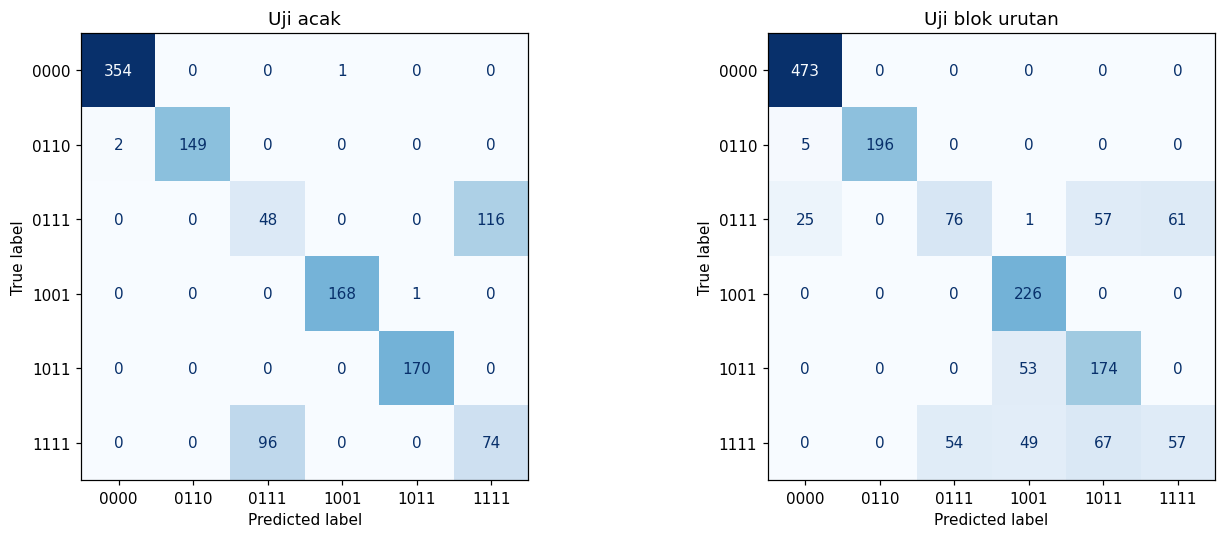

In [11]:
def evaluate_split(name, X_part, y_part):
    pred = best_model.predict(X_part)
    metrics = {'split': name, 'n_samples': len(y_part),
               'accuracy': accuracy_score(y_part, pred),
               'balanced_accuracy': balanced_accuracy_score(y_part, pred),
               'precision_macro': precision_score(y_part, pred, average='macro', zero_division=0),
               'recall_macro': recall_score(y_part, pred, average='macro', zero_division=0),
               'f1_macro': f1_score(y_part, pred, average='macro', zero_division=0),
               'f1_weighted': f1_score(y_part, pred, average='weighted', zero_division=0)}
    report = classification_report(y_part, pred, labels=CLASSES,
                                   target_names=[c + ' ' + CLASS_NAMES[c] for c in CLASSES],
                                   output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(OUT / f'classification_report_{name}.csv')
    details = X_part.copy()
    details.insert(0, 'row_id', X_part.index)
    details['true_code'], details['predicted_code'] = y_part.to_numpy(), pred
    details['correct'] = details['true_code'].eq(details['predicted_code'])
    details.to_csv(OUT / f'prediksi_{name}.csv', index=False)
    print('\n', name)
    print(classification_report(y_part, pred, labels=CLASSES, zero_division=0))
    return metrics, pred

random_metrics, pred_random = evaluate_split('test_random', X_test, y_test)
block_metrics, pred_block = evaluate_split('test_block', X_block, y_block)
holdout_metrics = pd.DataFrame([random_metrics, block_metrics])
holdout_metrics.to_csv(OUT / 'metrik_holdout.csv', index=False)
print(holdout_metrics.round(5).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name, truth, pred in [(axes[0], 'Uji acak', y_test, pred_random),
                              (axes[1], 'Uji blok urutan', y_block, pred_block)]:
    ConfusionMatrixDisplay.from_predictions(truth, pred, labels=CLASSES,
                                           display_labels=CLASSES, ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrix.png', bbox_inches='tight')
plt.show()


In [12]:
feature_estimator = best_model.named_steps['model']
if hasattr(feature_estimator, 'feature_importances_'):
    importance = pd.Series(feature_estimator.feature_importances_, index=FEATURES).sort_values()
    importance.rename('impurity_importance').to_csv(OUT / 'feature_importance.csv')
    fig, ax = plt.subplots(figsize=(7, 4))
    importance.plot.barh(ax=ax, color='#276c9b')
    ax.set(title='Feature importance model pohon', xlabel='Importance berbasis impurity')
    fig.tight_layout()
    fig.savefig(OUT / 'feature_importance.png', bbox_inches='tight')
    plt.show()
    print('Importance adalah asosiasi model dan dapat bias; bukan bukti sebab-akibat.')
else:
    print('Model terpilih tidak memiliki feature_importances_; tidak dipaksakan.')
print('Selisih macro F1 uji acak - uji blok:', round(random_metrics['f1_macro'] - block_metrics['f1_macro'], 5))


Model terpilih tidak memiliki feature_importances_; tidak dipaksakan.
Selisih macro F1 uji acak - uji blok: 0.08407


## 5. Menyimpan pipeline dan kontrak input
Satu file `.joblib` menyimpan imputasi, scaling, dan estimator. Output tetap kode string GCBA
agar angka nol di depan tidak hilang. Metadata mencatat urutan fitur, pemetaan kelas, versi paket,
hash data, parameter, hasil evaluasi, dan rentang fitur train.

Model yang diekspor adalah model train yang **sama** dengan model yang dievaluasi. Tidak ada
refit menggunakan test. Cocokkan versi Python dan paket ketika memuat di Jetson. Ketersediaan
paket pada versi OS/JetPack Bryan perlu diuji; jika tidak cocok, gunakan lingkungan training
yang kompatibel dan latih ulang. Notebook ini tidak menjamin kompatibilitas semua tipe Jetson.


In [13]:
model_path = OUT / 'model_pipeline.joblib'
joblib.dump(best_model, model_path, compress=3)
versions = {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
            'joblib': joblib.__version__}
metadata = {
    'project': 'Klasifikasi gangguan listrik tiga fase',
    'dataset_url': 'https://www.kaggle.com/datasets/esathyaprakash/electrical-fault-detection-and-classification',
    'dataset_file': source_name, 'dataset_sha256': source_sha256,
    'model_sha256': hashlib.sha256(model_path.read_bytes()).hexdigest(),
    'feature_order': FEATURES, 'label_order': LABEL_COLS, 'class_names': CLASS_NAMES,
    'versions': versions, 'seed': SEED, 'selected_model': winner,
    'selected_params': search.best_params_, 'best_cv_macro_f1': float(search.best_score_),
    'holdout_metrics': holdout_metrics.to_dict(orient='records'),
    'split_counts': split_manifest['split'].value_counts().to_dict(),
    'train_feature_ranges': {f: {'min': float(X_train[f].min()), 'max': float(X_train[f].max())}
                             for f in FEATURES},
    'limitations': ['Data simulasi, bukan validasi sensor nyata.',
                    'Tidak ada timestamp atau ID kejadian terverifikasi; uji blok hanya memakai urutan baris.',
                    'CV acak masih mungkin optimistis untuk sampel yang berkorelasi.',
                    'Label kondisi saat ini, bukan perkiraan waktu gangguan di masa depan.'],
}
(OUT / 'metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
(OUT / 'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k, v in versions.items() if k != 'python') + '\n', encoding='utf-8')
example_idx = y_test.groupby(y_test).head(1).index
examples = X_test.loc[example_idx, FEATURES]
examples.to_csv(OUT / 'contoh_input.csv', index=False)
pd.DataFrame({'example_row': range(len(examples)), 'true_code': y_test.loc[example_idx].values,
              'true_name': y_test.loc[example_idx].map(CLASS_NAMES).values}).to_csv(OUT / 'contoh_label_referensi.csv', index=False)
reloaded = joblib.load(model_path)
np.testing.assert_array_equal(reloaded.predict(X_test), pred_random)
print('Model berhasil disimpan dan dimuat. Seluruh prediksi uji acak tetap identik.')
print('Versi lingkungan:', versions)


Model berhasil disimpan dan dimuat. Seluruh prediksi uji acak tetap identik.
Versi lingkungan: {'python': '3.13.18', 'scikit-learn': '1.6.1', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'joblib': '1.6.0'}


### Membuat `main_deploy.py`
Skrip ini menerima CSV atau enam angka, memuat pipeline, dan menghasilkan JSON prediksi.
Fungsi `predict_frame` dapat dipanggil Arif dari API, setelah model dimuat sekali saat aplikasi
mulai. Skrip tidak membuka server web dan tidak memiliki proses training.


In [14]:
DEPLOY_SOURCE = r'''
"""Inferensi mandiri: muat pipeline tanpa melatih ulang.
Contoh: python main_deploy.py --input contoh_input.csv --output hasil_prediksi.csv
Contoh: python main_deploy.py --values -151.2 -9.6 85.8 0.40 -0.13 -0.26
Jalankan hanya model dari sumber yang dipercaya.
"""
from pathlib import Path
import argparse
import json
import numpy as np
import pandas as pd
import joblib

BASE = Path(__file__).resolve().parent

def load_artifacts(model_path=None, metadata_path=None):
    model_path = Path(model_path) if model_path else BASE / 'model_pipeline.joblib'
    metadata_path = Path(metadata_path) if metadata_path else BASE / 'metadata.json'
    model = joblib.load(model_path)
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    return model, metadata

def predict_frame(frame, model, metadata):
    features = metadata['feature_order']
    missing = [f for f in features if f not in frame.columns]
    if missing:
        raise ValueError('Kolom input belum lengkap: ' + ', '.join(missing))
    X = frame.loc[:, features].apply(pd.to_numeric, errors='raise')
    if X.empty or not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError('Input harus berisi angka hingga, tidak kosong, dan tanpa NaN/inf.')
    codes = model.predict(X)
    result = pd.DataFrame({'fault_code': codes})
    result['fault_name'] = result['fault_code'].map(metadata['class_names'])
    return result

def main():
    parser = argparse.ArgumentParser(description='Prediksi gangguan listrik tanpa training ulang.')
    source = parser.add_mutually_exclusive_group(required=True)
    source.add_argument('--input', type=Path, help='CSV dengan enam kolom fitur.')
    source.add_argument('--values', nargs=6, type=float, metavar='N', help='Urutan Ia Ib Ic Va Vb Vc.')
    parser.add_argument('--model', type=Path)
    parser.add_argument('--metadata', type=Path)
    parser.add_argument('--output', type=Path)
    args = parser.parse_args()
    model, metadata = load_artifacts(args.model, args.metadata)
    frame = (pd.read_csv(args.input) if args.input else
             pd.DataFrame([args.values], columns=metadata['feature_order']))
    result = predict_frame(frame, model, metadata)
    if args.output:
        args.output.parent.mkdir(parents=True, exist_ok=True)
        result.to_csv(args.output, index=False)
    print(result.to_json(orient='records', force_ascii=False))

if __name__ == '__main__':
    main()
'''
(OUT / "main_deploy.py").write_text(DEPLOY_SOURCE, encoding="utf-8")
print("main_deploy.py selesai dibuat.")


main_deploy.py selesai dibuat.


### Verifikasi deployment sebagai proses terpisah
Uji berikut menjalankan `main_deploy.py` melalui Python baru. Semua prediksi harus sama dengan
pipeline notebook. Pengujian ini memeriksa load model dan inferensi mandiri; performa/kompatibilitas
Jetson harus diukur langsung pada perangkat oleh Bryan.


In [15]:
X_test.to_csv(OUT / 'uji_input_mandiri.csv', index=False)
process = subprocess.run(
    [sys.executable, str(OUT / 'main_deploy.py'), '--input', str(OUT / 'uji_input_mandiri.csv'),
     '--output', str(OUT / 'uji_output_mandiri.csv')],
    check=True, capture_output=True, text=True)
cli_prediction = pd.read_csv(OUT / 'uji_output_mandiri.csv', dtype={'fault_code': str})
np.testing.assert_array_equal(cli_prediction['fault_code'].to_numpy(), pred_random)
print('LULUS: inferensi mandiri cocok untuk', len(X_test), 'sampel holdout.')
print(cli_prediction.head().to_string(index=False))
# Validasi jalur enam angka dengan sampel nyata dari holdout, bukan angka buatan.
sample = X_test.iloc[0]
process_single = subprocess.run(
    [sys.executable, str(OUT / 'main_deploy.py'), '--values'] + [str(v) for v in sample],
    check=True, capture_output=True, text=True)
assert json.loads(process_single.stdout)[0]['fault_code'] == pred_random[0]
print('LULUS: jalur --values enam angka.')


LULUS: inferensi mandiri cocok untuk 1179 sampel holdout.
fault_code                  fault_name
      1001        A-G: fase A ke tanah
      0000                      Normal
      0000                      Normal
      1011 AB-G: fase A dan B ke tanah
      0000                      Normal
LULUS: jalur --values enam angka.


## 6. Ringkasan hasil, dokumentasi, dan paket unduhan
Ringkasan di bawah dihitung dari hasil eksekusi, bukan angka contoh. Untuk laporan 5–8 halaman,
gunakan latar belakang, sumber dan keterbatasan data, preprocessing/fitur, metode validasi,
hasil dan analisis kesalahan, deployment, serta kesimpulan. Tambahkan link video YouTube sendiri
setelah kelompok merekam penjelasan dan demonstrasi.


In [16]:
report_text = f"""RINGKASAN EKSPERIMEN
Model terpilih menurut CV train: {winner}
Parameter: {search.best_params_}
CV macro F1 pemilihan parameter: {search.best_score_:.4f}
Uji acak - accuracy: {random_metrics['accuracy']:.4f}; macro F1: {random_metrics['f1_macro']:.4f}
Uji blok - accuracy: {block_metrics['accuracy']:.4f}; macro F1: {block_metrics['f1_macro']:.4f}
Total data: {len(df)}. Pembagian: {metadata['split_counts']}

Interpretasi wajib: bandingkan train dan CV; jelaskan kelas yang tertukar pada confusion matrix;
bandingkan uji acak dan uji blok. Skor rendah pada uji blok perlu dilaporkan, bukan dihapus.
Seluruh data adalah benchmark simulasi. Belum ada validasi sensor nyata, kejadian simulasi baru,
atau pengukuran latensi Jetson. Tidak ada klaim bahwa sistem siap sebagai proteksi jaringan nyata.
"""
print(report_text)
(OUT / 'ringkasan_hasil.txt').write_text(report_text, encoding='utf-8')
readme = f"""# Paket Klasifikasi Gangguan Listrik Tiga Fase

## Cara menjalankan
Lingkungan pembuat: Python {versions['python']}, scikit-learn {versions['scikit-learn']}.
1. Siapkan lingkungan Python yang kompatibel dengan versi paket pada requirements.txt.
2. Pasang dependensi: python -m pip install -r requirements.txt
3. Jalankan: python main_deploy.py --input contoh_input.csv --output hasil_prediksi.csv
4. Untuk input angka: python main_deploy.py --values <Ia> <Ib> <Ic> <Va> <Vb> <Vc>

Jangan mengetik tanda < >; ganti dengan angka. main_deploy.py tidak melatih ulang model.
Untuk integrasi API: model, metadata = load_artifacts(); kemudian panggil
predict_frame(frame, model, metadata) dan ubah hasilnya menjadi JSON.

## Berkas
- model_pipeline.joblib: pipeline preprocessing dan model yang dievaluasi.
- metadata.json: urutan fitur, kelas, versi paket, hash, parameter, dan metrik.
- main_deploy.py: inferensi CSV/angka mandiri.
- contoh_input.csv: satu sampel uji per kelas; bukan label untuk dimasukkan ke model.
- contoh_label_referensi.csv: jawaban acuan untuk contoh, bukan input model.
- metrik_holdout.csv, classification_report_*.csv, prediksi_*.csv: hasil evaluasi.
- split_manifest.csv: pembagian baris setelah pembersihan.
- perbandingan_cv.csv, hasil_tuning.csv, *.png: bahan analisis laporan.
- ringkasan_hasil.txt: ringkasan hasil yang dihitung saat eksekusi.

## Pembagian kerja
Reno: dataset dan model. Arif: web/API. Bryan: Jetson dan deployment.
Anggota 4: preprocessing/fitur. Anggota 5: evaluasi/validasi.
Anggota 6: integrasi, dokumentasi, laporan 5–8 halaman, dan video YouTube.
Semua anggota memahami kode dan menulis penjelasan bagiannya.

## Batasan dan reproduksibilitas
Sumber: {metadata['dataset_url']}
File: {source_name}; SHA-256: {source_sha256}
Data simulasi; unit/skala sensor harus dikonfirmasi, tidak boleh langsung disamakan dengan sensor fisik.
Holdout acak dan holdout blok tidak digunakan untuk training atau tuning; model ekspor sama
dengan model evaluasi. Nomor baris bukan timestamp atau ID kejadian.
Perlu validasi pada kejadian dan sensor baru sebelum klaim kemampuan di lapangan.
Bryan perlu menguji kompatibilitas paket dengan OS/JetPack perangkat. Jika versi ini tidak
tersedia pada Jetson, buat ulang lingkungan training yang kompatibel dan latih ulang;
jangan menganggap file joblib mendukung perbedaan versi scikit-learn.
Gunakan model joblib hanya dari sumber yang dipercaya.
Sertakan notebook .ipynb dari Colab, laporan, dan tautan video saat mengumpulkan tugas.
"""
(OUT / 'README.md').write_text(readme, encoding='utf-8')
package = OUT / 'paket_deployment.zip'
with zipfile.ZipFile(package, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT.iterdir()):
        if path.is_file() and path.suffix != '.zip':
            z.write(path, arcname=path.name)
print('Paket siap:', package)
print('Ukuran paket:', round(package.stat().st_size / 1024, 1), 'KiB')
print('Jalankan sel terakhir untuk mengunduh paket hasil.')


RINGKASAN EKSPERIMEN
Model terpilih menurut CV train: KNN
Parameter: {'model__n_neighbors': 15, 'model__weights': 'uniform'}
CV macro F1 pemilihan parameter: 0.7973
Uji acak - accuracy: 0.8168; macro F1: 0.7838
Uji blok - accuracy: 0.7637; macro F1: 0.6998
Total data: 7861. Pembagian: {'train': 4714, 'test_block': 1574, 'test_random': 1179, 'purge': 394}

Interpretasi wajib: bandingkan train dan CV; jelaskan kelas yang tertukar pada confusion matrix;
bandingkan uji acak dan uji blok. Skor rendah pada uji blok perlu dilaporkan, bukan dihapus.
Seluruh data adalah benchmark simulasi. Belum ada validasi sensor nyata, kejadian simulasi baru,
atau pengukuran latensi Jetson. Tidak ada klaim bahwa sistem siap sebagai proteksi jaringan nyata.

Paket siap: /content/hasil_gangguan_listrik/paket_deployment.zip
Ukuran paket: 756.9 KiB
Jalankan sel terakhir untuk mengunduh paket hasil.


## Catatan pemahaman dan pekerjaan berikutnya
Sebelum dikumpulkan, setiap anggota perlu dapat menjelaskan:
1. Mengapa GCBA adalah label dan tidak masuk X?
2. Mengapa nilai ekstrem tidak langsung dibuang?
3. Mengapa scaler di-fit di dalam pipeline CV?
4. Mengapa macro F1 dan recall per kelas dibaca selain accuracy?
5. Mengapa uji acak dan uji blok dapat berbeda?
6. Mengapa load model pada Jetson memerlukan pemeriksaan versi dependensi?

**Belum dibuat oleh notebook:** aplikasi web, uji pada Jetson, laporan final, video, dan publikasi YouTube.
Isi nama tiga anggota lainnya pada laporan dan dokumentasi tim.

### Referensi
- Dataset: https://www.kaggle.com/datasets/esathyaprakash/electrical-fault-detection-and-classification
- Google Colab: https://research.google.com/colaboratory/intl/id/faq.html
- Scikit-Learn, Pipeline: https://scikit-learn.org/stable/modules/compose.html
- Scikit-Learn, Cross-validation: https://scikit-learn.org/stable/modules/cross_validation.html
- Scikit-Learn, Model persistence: https://scikit-learn.org/stable/model_persistence.html


## 7. Unduh hasil untuk Arif dan Bryan
Jalankan sel berikut setelah semua proses selesai. Unduh notebook yang sudah berisi hasil juga
melalui **File > Download > Download .ipynb** untuk pengumpulan tugas.
Paket ZIP berisi model, skrip deployment, dependensi, metadata, contoh input, dan hasil evaluasi.


In [17]:
package_path = OUT / 'paket_deployment.zip'
if not package_path.is_file():
    raise FileNotFoundError('Paket belum dibuat. Jalankan semua sel sebelumnya sampai selesai.')
if IN_COLAB:
    colab_files.download(str(package_path))
else:
    print('Paket tersedia:', package_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>